In [1]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer

In [2]:
# Natural Earth
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url)

In [3]:
# Loximuthal projection
crs = "+proj=loxim +lat_1=40 +lon_0=0 +datum=WGS84 +units=m +type=crs"
# Reproject
world = world.to_crs(crs)
# Convert to Loximuthal coords
transformer = Transformer.from_crs("EPSG:4326", crs, always_xy=True)

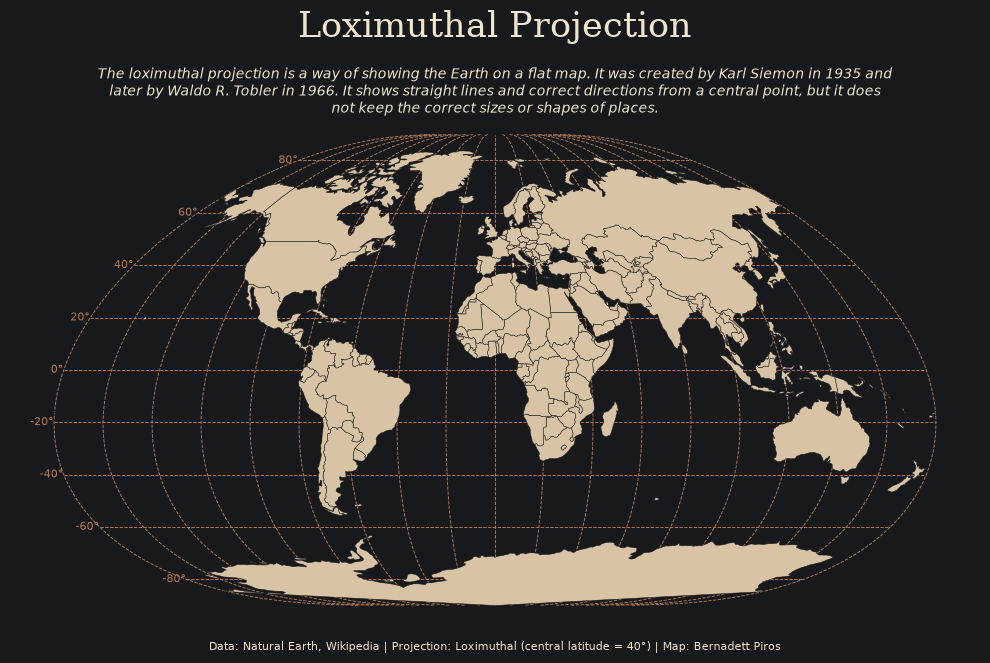

In [4]:
fig, ax = plt.subplots(figsize=(10, 8), facecolor="#17191C")

# Lat lines
for lat in range(-80, 81, 20):

    lons = np.linspace(-180, 180, 500)
    x, y = transformer.transform(lons, np.full(500, lat))

    ax.plot(x, y, color="#B77B52", lw=0.65, ls="--")

    # Lat labels
    x_label, y_label = transformer.transform(-180, lat)
    ax.text(x_label, y_label, f"{lat}°", color="#B77B52", size=8, ha="right", va="center")

# Lon lines
for lon in range(-180, 181, 20):

    lats = np.linspace(-89.9, 89.9, 500)
    x, y = transformer.transform(np.full(500, lon), lats)

    ax.plot(x, y, color="#B77B52", lw=0.65, ls="--")

# Countries
world.plot(ax=ax, color="#D8C3A5", ec="#17191C", lw=0.35, zorder=2)


ax.set_aspect("equal")
ax.set_facecolor("#17191C")
ax.axis("off")

# Title
fig.text(0.5, 0.95,
    "Loximuthal Projection",
    fontsize=25, color="#F0E6CE", fontfamily="serif", ha="center", va="top")

# Subtitle
fig.text(0.5, 0.88,
         "The loximuthal projection is a way of showing the Earth on a flat map. It was created by Karl Siemon in 1935 and\n"
         "later by Waldo R. Tobler in 1966. It shows straight lines and correct directions from a central point, but it does\n"
         "not keep the correct sizes or shapes of places.",
          color="#F0E6CE", size=10, style="italic", ha="center", va="top")

# Caption
fig.text(0.5, 0.15,
         "Data: Natural Earth, Wikipedia | Projection: Loximuthal (central latitude = 40°) | Map: Bernadett Piros",
         color="#F0E6CE", size=8, ha="center")

plt.tight_layout()
plt.show()

#fig.savefig("loximuthal.png", bbox_inches="tight", pad_inches=0.2)